# Parameter Estimation in a Synthetic Response Model

## Overview
I carried out this learning exercise to explore how measurement noise and initial parameter values affect parameter estimation in a simple temporal model.

Using Python, I generated a synthetic response to a brief stimulus and estimated two parameters: gain and time constant. I then examined how the estimates changed across repeated noisy measurements and different optimization starting points.

## Experiments
1. Recover known parameters from a noisy synthetic signal.
2. Compare parameter estimates across three noise levels, with 50 repetitions per level.
3. Fit the same signal from six different starting points.

## Tools
Python, NumPy, SciPy, and Matplotlib.

## Scope and limitations
This notebook uses synthetic data, not human physiological recordings. The same model is used to generate and fit the data. The results therefore describe this simulation and do not establish performance on real physiological signals.

## Acknowledgment
I used ChatGPT to help prepare the code and explain the methods. I ran the experiments in Google Colab and am using this notebook to develop my understanding of temporal modeling and numerical optimization.




## Experiment 1 — Recovering Known Parameters

In this first experiment, I generated a synthetic response to a one-second stimulus using a simple exponential response kernel.

I set the true gain to **1.5** and the true time constant to **1.2 seconds**. After adding Gaussian noise with a standard deviation of **0.04**, I fitted the model using SciPy’s `least_squares` function.

The estimated gain was approximately **1.492**, and the estimated time constant was approximately **1.211 seconds**. The fitted curve closely followed the noise-free response.

This provides an initial check that the fitting procedure can recover parameters under these simulation conditions. Further experiments examine sensitivity to noise and starting values.

Gerçek kazanç: 1.500
Tahmin edilen kazanç: 1.492

Gerçek zaman sabiti: 1.200 saniye
Tahmin edilen zaman sabiti: 1.211 saniye

Optimizasyon tamamlandı mı? True


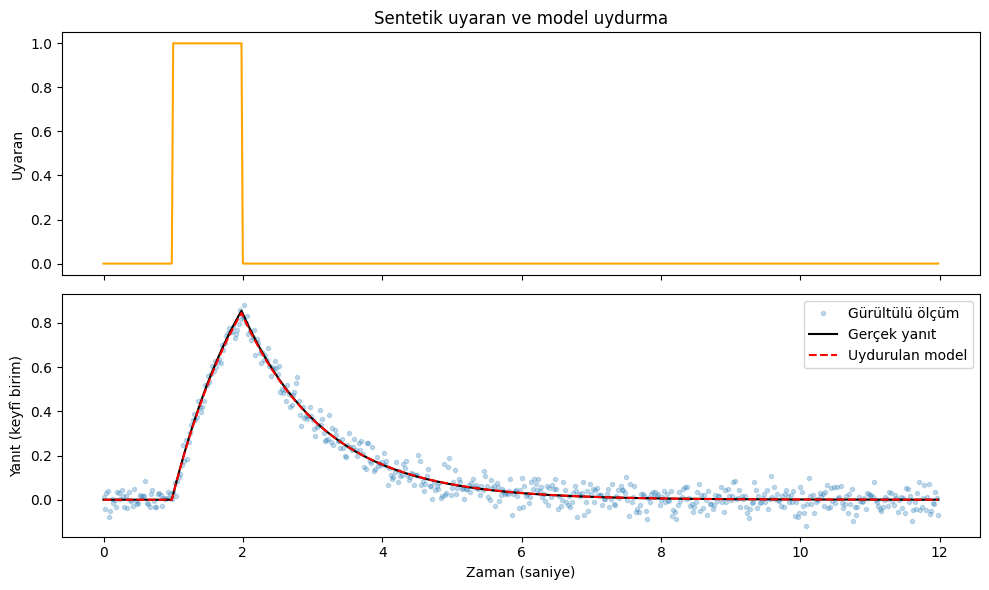

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import convolve
from scipy.optimize import least_squares

# 1. Zaman ve bir saniyelik uyaran
dt = 0.02
t = np.arange(0, 12, dt)
stimulus = ((t >= 1) & (t < 2)).astype(float)

# 2. Basit yanıt modeli
# gain: yanıtın ölçeği
# tau: yanıtın sönüm hızını belirleyen zaman sabiti
def response(parameters):
    gain, tau = parameters
    kernel = np.exp(-t / tau) / tau
    return gain * convolve(stimulus, kernel, mode="full")[:len(t)] * dt

# 3. Parametrelerini bildiğimiz sentetik veri
true_parameters = [1.5, 1.2]
clean_signal = response(true_parameters)

rng = np.random.default_rng(42)
observed_signal = clean_signal + rng.normal(0, 0.04, size=len(t))

# 4. Parametreleri yalnızca gürültülü veriden kestir
result = least_squares(
    lambda parameters: response(parameters) - observed_signal,
    x0=[0.7, 0.5],
    bounds=([0.01, 0.05], [5.0, 5.0])
)

estimated_signal = response(result.x)

print(f"Gerçek kazanç: {true_parameters[0]:.3f}")
print(f"Tahmin edilen kazanç: {result.x[0]:.3f}")
print(f"\nGerçek zaman sabiti: {true_parameters[1]:.3f} saniye")
print(f"Tahmin edilen zaman sabiti: {result.x[1]:.3f} saniye")
print(f"\nOptimizasyon tamamlandı mı? {result.success}")

# 5. Sonuçları gör
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

axes[0].plot(t, stimulus, color="orange")
axes[0].set_ylabel("Uyaran")
axes[0].set_title("Sentetik uyaran ve model uydurma")

axes[1].plot(t, observed_signal, ".", alpha=0.25,
             label="Gürültülü ölçüm")
axes[1].plot(t, clean_signal, color="black",
             label="Gerçek yanıt")
axes[1].plot(t, estimated_signal, "--", color="red",
             label="Uydurulan model")
axes[1].set_xlabel("Zaman (saniye)")
axes[1].set_ylabel("Yanıt (keyfî birim)")
axes[1].legend()

plt.tight_layout()
plt.show()

## Experiment 2 — Effect of Measurement Noise

I examined parameter estimation at three Gaussian noise levels: **0.04, 0.15, and 0.30**. At each level, I generated 50 independent noisy signals and fitted the model using the same starting values.

As noise increased, the parameter estimates became more spread out. Their means remained close to the true values, while their standard deviations and RMSE values increased.

All 150 optimization runs met a stopping criterion. However, this did not mean that every parameter estimate was equally accurate. The experiment illustrates how measurement noise can increase estimation variability even when optimization completes successfully.

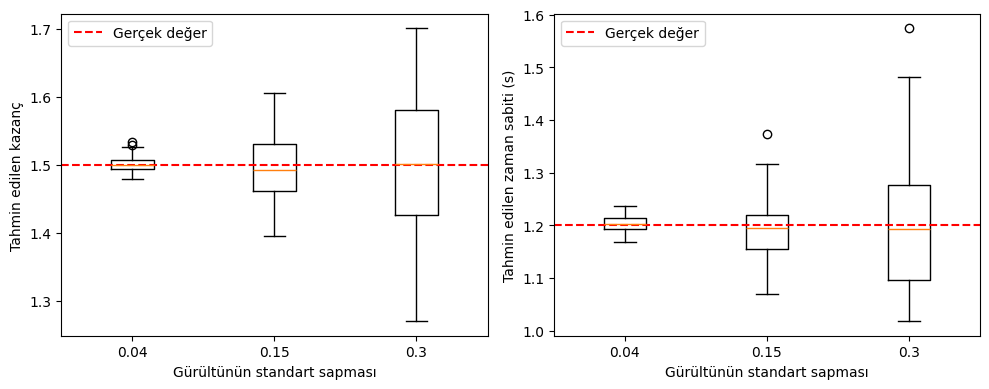

Gürültü 0.04: 50/50 başarılı optimizasyon
Gürültü 0.15: 50/50 başarılı optimizasyon
Gürültü 0.3: 50/50 başarılı optimizasyon


In [11]:
# Üç gürültü düzeyi, her düzeyde 50 bağımsız tekrar
noise_levels = [0.04, 0.15, 0.30]
rng_test = np.random.default_rng(123)
estimates = []

for noise in noise_levels:
    level_estimates = []

    for repeat in range(50):
        noisy_signal = clean_signal + rng_test.normal(
            0, noise, size=len(t)
        )

        fit = least_squares(
            lambda parameters: response(parameters) - noisy_signal,
            x0=[0.7, 0.5],
            bounds=([0.01, 0.05], [5.0, 5.0])
        )

        # Başarısız optimizasyonları sonuçtan gizlemiyoruz.
        if fit.success:
            level_estimates.append(fit.x)
        else:
            level_estimates.append([np.nan, np.nan])

    estimates.append(np.array(level_estimates))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
labels = [str(level) for level in noise_levels]

for parameter_index, ax in enumerate(axes):
    values = [
        result[:, parameter_index][
            np.isfinite(result[:, parameter_index])
        ]
        for result in estimates
    ]

    ax.boxplot(values, tick_labels=labels)
    ax.axhline(
        true_parameters[parameter_index],
        color="red", linestyle="--", label="Gerçek değer"
    )
    ax.set_xlabel("Gürültünün standart sapması")
    ax.legend()

axes[0].set_ylabel("Tahmin edilen kazanç")
axes[1].set_ylabel("Tahmin edilen zaman sabiti (s)")
plt.tight_layout()
plt.show()

for noise, result in zip(noise_levels, estimates):
    successful = np.isfinite(result[:, 0]).sum()
    print(f"Gürültü {noise}: {successful}/50 başarılı optimizasyon")

In [12]:
for noise, parameter_estimates in zip(noise_levels, estimates):
    print(f"\nGürültü: {noise}")

    for j, name in enumerate(["Kazanç", "Zaman sabiti"]):
        values = parameter_estimates[:, j]
        values = values[np.isfinite(values)]

        if len(values) == 0:
            print(f"{name}: geçerli tahmin yok")
            continue

        errors = values - true_parameters[j]

        print(
            f"{name}: "
            f"ortalama={np.mean(values):.3f}, "
            f"standart sapma={np.std(values, ddof=1):.3f}, "
            f"RMSE={np.sqrt(np.mean(errors**2)):.3f}"
        )


Gürültü: 0.04
Kazanç: ortalama=1.502, standart sapma=0.013, RMSE=0.013
Zaman sabiti: ortalama=1.203, standart sapma=0.015, RMSE=0.015

Gürültü: 0.15
Kazanç: ortalama=1.494, standart sapma=0.047, RMSE=0.047
Zaman sabiti: ortalama=1.196, standart sapma=0.061, RMSE=0.061

Gürültü: 0.3
Kazanç: ortalama=1.500, standart sapma=0.103, RMSE=0.102
Zaman sabiti: ortalama=1.204, standart sapma=0.127, RMSE=0.126


## Experiment 3 — Sensitivity to Initial Values

I fitted one fixed noisy signal from six different starting points. I kept the signal, model, and parameter bounds unchanged so that only the initial parameter values varied.

All six runs produced the same estimates to the displayed precision: a gain of **1.5410** and a time constant of **1.2911 seconds**, with an MSE of approximately **0.024783**.

For this signal and the tested starting points, the estimates showed little sensitivity to initialization. This does not establish that every possible starting point would produce the same solution.

The gray lines connect each starting point to its final estimate; they do not show the optimizer’s intermediate steps.

Başlangıç       → Tahmin          | MSE      | Tamamlandı
--------------------------------------------------------------------
[0.1, 0.1] → [1.5410, 1.2911] | 0.024783 | True
[0.5, 3.0] → [1.5410, 1.2911] | 0.024783 | True
[1.0, 1.0] → [1.5410, 1.2911] | 0.024783 | True
[2.0, 0.3] → [1.5410, 1.2911] | 0.024783 | True
[3.0, 4.0] → [1.5410, 1.2911] | 0.024783 | True
[4.5, 4.5] → [1.5410, 1.2911] | 0.024783 | True


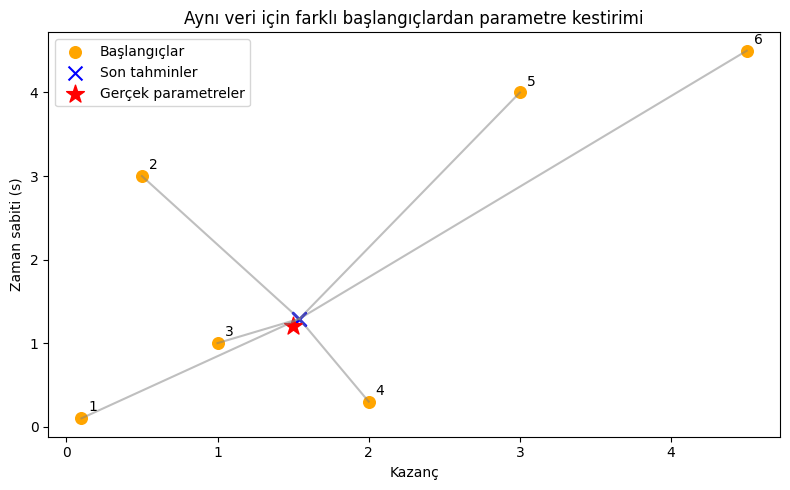

In [13]:
# 1. Tek bir gürültülü ölçüm oluştur; bütün denemelerde bunu kullan.
rng_start_test = np.random.default_rng(2026)
fixed_signal = clean_signal + rng_start_test.normal(
    0, 0.15, size=len(t)
)

# Her çift: [başlangıç kazancı, başlangıç zaman sabiti]
starting_points = [
    [0.1, 0.1],
    [0.5, 3.0],
    [1.0, 1.0],
    [2.0, 0.3],
    [3.0, 4.0],
    [4.5, 4.5]
]

start_results = []

print("Başlangıç       → Tahmin          | MSE      | Tamamlandı")
print("-" * 68)

# 2. Aynı veriye, farklı başlangıçlardan model uydur.
for start in starting_points:
    fit = least_squares(
        lambda parameters: response(parameters) - fixed_signal,
        x0=start,
        bounds=([0.01, 0.05], [5.0, 5.0])
    )

    mse = np.mean((response(fit.x) - fixed_signal) ** 2)
    start_results.append(fit.x)

    print(
        f"[{start[0]:.1f}, {start[1]:.1f}]"
        f" → [{fit.x[0]:.4f}, {fit.x[1]:.4f}]"
        f" | {mse:.6f} | {fit.success}"
    )

# 3. Başlangıç noktalarını ve son tahminleri karşılaştır.
start_results = np.array(start_results)
starts = np.array(starting_points)

plt.figure(figsize=(8, 5))

for i, (start, estimate) in enumerate(zip(starts, start_results)):
    plt.plot(
        [start[0], estimate[0]],
        [start[1], estimate[1]],
        color="gray", alpha=0.5
    )
    plt.annotate(str(i + 1), start, xytext=(5, 5),
                 textcoords="offset points")

plt.scatter(starts[:, 0], starts[:, 1],
            color="orange", label="Başlangıçlar", s=70)

plt.scatter(start_results[:, 0], start_results[:, 1],
            color="blue", marker="x", s=100, label="Son tahminler")

plt.scatter(*true_parameters, color="red", marker="*",
            s=180, label="Gerçek parametreler")

plt.xlabel("Kazanç")
plt.ylabel("Zaman sabiti (s)")
plt.title("Aynı veri için farklı başlangıçlardan parametre kestirimi")
plt.legend()
plt.tight_layout()
plt.show()

## Conclusions

In these simulations, increasing measurement noise increased the variability and RMSE of the estimated parameters, while the mean estimates remained close to the true values.

For one fixed noisy signal, all six tested starting points produced the same parameter estimates to the displayed precision. This suggests limited sensitivity to initialization under the tested conditions.

These experiments helped me distinguish between optimization completion, parameter accuracy, and variability across repeated measurements. An optimizer meeting a stopping criterion does not guarantee an accurate parameter estimate.

## Limitations and Next Steps

This exercise uses a simple model and synthetic data generated by that same model. It does not test model mismatch, missing observations, or real physiological recordings.

Possible next steps include examining shorter recording windows, fitting data generated by a different response kernel, and investigating whether similar fit errors can occur with different parameter estimates.